# Ny notatbok

Skriv kode i cellene under, og kjør dem med **Shift+Enter**.

[[[142 148 159]
  [140 146 157]
  [142 148 159]
  ...
  [149 150 154]
  [149 150 154]
  [142 143 147]]

 [[143 149 160]
  [143 149 160]
  [147 153 164]
  ...
  [151 152 156]
  [148 149 153]
  [149 150 154]]

 [[146 152 163]
  [143 149 160]
  [147 153 164]
  ...
  [150 151 155]
  [151 152 156]
  [150 151 155]]

 ...

 [[ 65 123 175]
  [ 59 117 169]
  [ 63 121 173]
  ...
  [ 97 141 178]
  [ 97 141 178]
  [103 147 184]]

 [[ 60 119 169]
  [ 65 124 174]
  [ 50 108 160]
  ...
  [ 99 143 180]
  [ 95 139 176]
  [101 145 182]]

 [[ 52 111 161]
  [ 64 123 173]
  [ 39  97 149]
  ...
  [111 155 192]
  [103 147 184]
  [103 147 184]]]: 8 books detected.


celle 3:74: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


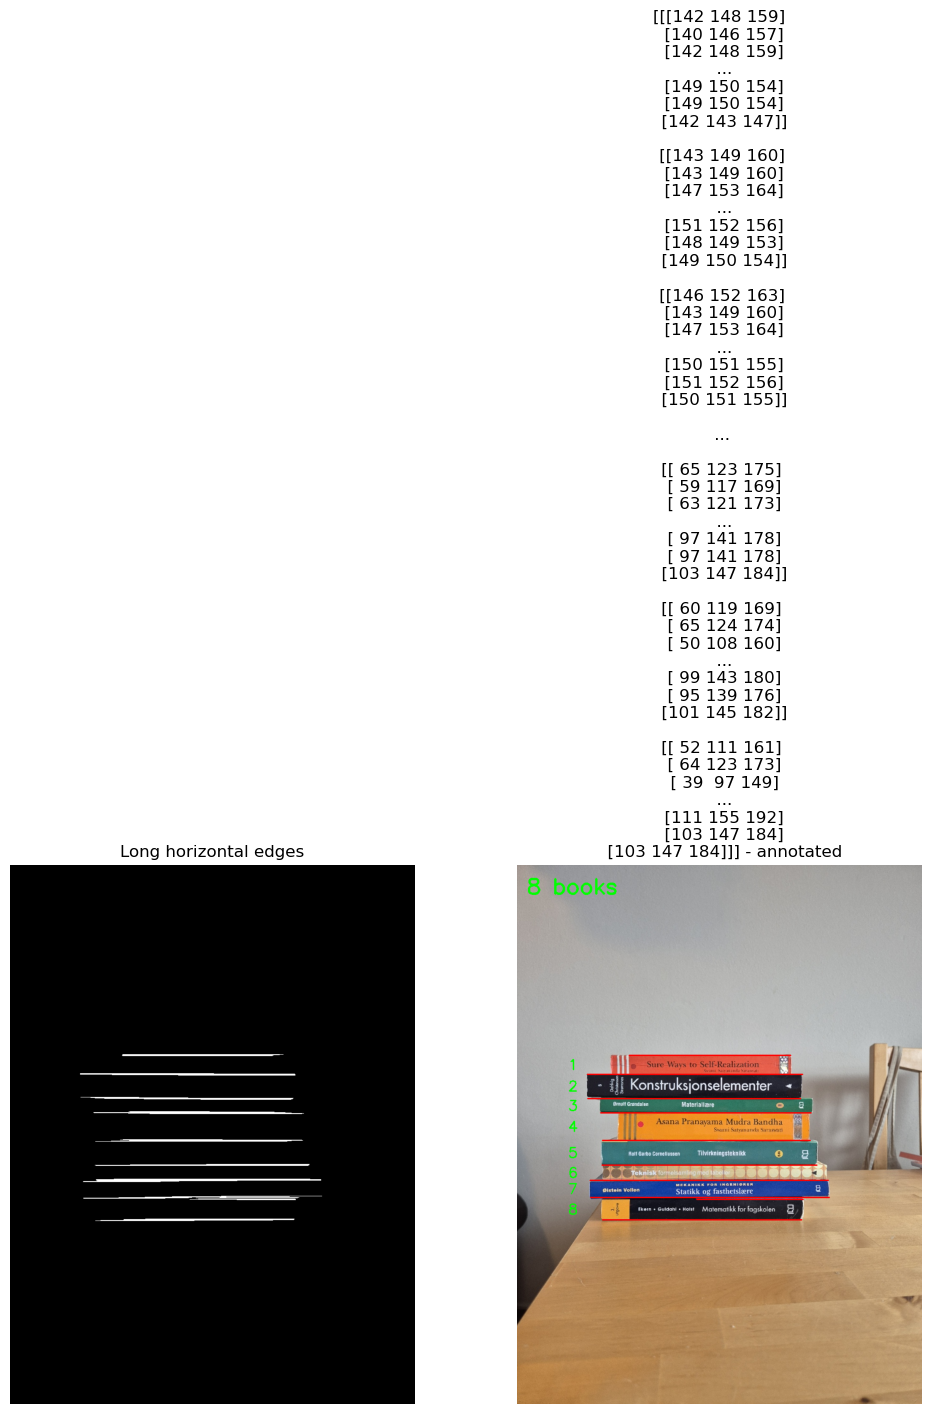

In [3]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from ipywidgets import interact
import fargelab



# Write the name of the image file you want to analyze (the file must be in the same folder as this script)
IMAGE_NAME = cv2.imread('stack_2.png')

# How strong a color change between two rows must be to count as an edge
EDGE_STRENGTH_THRESHOLD = 80
# A boundary between two books is a long horizontal edge. Shorter edges (text, wood grain) are ignored.
MIN_EDGE_LENGTH_PX = 120
# Two edges closer than this do not have room for a book between them
MIN_BOOK_THICKNESS_PX = 15

# image = IMAGE_NAME
# 1. Find the edges between the rows of the image.
# Lab color space is used because it measures color differences well, so the edge between two books
# is found even if the books have the same brightness but different colors.
blurred_image = cv2.GaussianBlur(image, (5, 5), 0)
lab_image = cv2.cvtColor(blurred_image, cv2.COLOR_BGR2LAB).astype(np.float32)

# Sobel in y direction gives the change from one row to the next, for each of the L, a and b channels.
# The three channels are combined into one edge strength for each pixel.
gradient_y = cv2.Sobel(lab_image, cv2.CV_32F, 0, 1, ksize=3)
edge_strength = np.sqrt((gradient_y ** 2).sum(axis=2))
edges = (edge_strength > EDGE_STRENGTH_THRESHOLD).astype(np.uint8) * 255

# 2. Keep only long horizontal edges: opening with a kernel that is 1 pixel high and
# MIN_EDGE_LENGTH_PX wide removes everything that is not a long horizontal line.
kernel = np.ones((1, MIN_EDGE_LENGTH_PX), np.uint8)
edges = cv2.morphologyEx(edges, cv2.MORPH_OPEN, kernel)

# Each long edge is one contour. Sort them from top to bottom.
contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
boundaries = []
for contour in contours:
    x, y, width, height = cv2.boundingRect(contour)
    boundaries.append((y + height // 2, x, x + width))
boundaries.sort()

# 3. A book is the space between two neighbouring boundaries. The top and bottom edge of the stack
# are boundaries too, so n books have n + 1 boundaries.
books = []
for (upper_y, _, _), (lower_y, _, _) in zip(boundaries[:-1], boundaries[1:]):
    if lower_y - upper_y >= MIN_BOOK_THICKNESS_PX:
        books.append((upper_y, lower_y))

print(f"{IMAGE_NAME}: {len(books)} books detected.")

# 4. Draw the result on a copy of the image
annotated_image = image.copy()
stack_left = min(left for _, left, _ in boundaries)
for boundary_y, left, right in boundaries:
    cv2.line(annotated_image, (left, boundary_y), (right, boundary_y), (0, 0, 255), 2)
for number, (upper_y, lower_y) in enumerate(books, start=1):
    cv2.putText(annotated_image, str(number), (stack_left - 40, (upper_y + lower_y) // 2 + 10),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2)
cv2.putText(annotated_image, f"{len(books)} books", (20, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 255, 0), 3)

figure, axes = plt.subplots(1, 2, figsize=(12, 7))
axes[0].imshow(edges, cmap="gray")
axes[0].set_title("Long horizontal edges")
axes[1].imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"{IMAGE_NAME} - annotated")
axes[0].axis("off")
axes[1].axis("off")
plt.tight_layout()
plt.show()
